# Complete Data Analysis and Linear Regression using Scikit-learn
## Project: California Housing Price Prediction

**Objective:** Explore a real-world dataset, perform data cleaning and exploratory data analysis, prepare features, train a Linear Regression model, evaluate it, and make predictions.

The California Housing dataset predicts median house value for California districts. The target is measured in units of **$100,000**.

## 1. Import libraries

In [ ]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing



## 2. Load the dataset

In [ ]:
housing = fetch_california_housing()

df = pd.DataFrame(
    housing.data,
    columns=housing.feature_names
)
df["Price"] = housing.target



In [ ]:
df.head(10)
df.tail()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Price
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847
20639,2.3886,16.0,5.254717,1.162264,1387.0,2.616981,39.37,-121.24,0.894


### Feature descriptions

| Feature | Description |
|---|---|
| MedInc | Median income in the district |
| HouseAge | Median house age |
| AveRooms | Average number of rooms |
| AveBedrms | Average number of bedrooms |
| Population | District population |
| AveOccup | Average household occupancy |
| Latitude | Geographical latitude |
| Longitude | Geographical longitude |
| Price | Median house value (in $100,000 units) |

In [ ]:
df.shape

(20640, 9)

## 3. Understand the dataset

### 3.1 Dataset dimensions

In [ ]:
print("Shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Shape: (20640, 9)
Number of rows: 20640
Number of columns: 9


### 3.2 View records

In [ ]:
display(df.head(10))

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Price
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
5,4.0368,52.0,4.761658,1.103627,413.0,2.139896,37.85,-122.25,2.697
6,3.6591,52.0,4.931907,0.951362,1094.0,2.128405,37.84,-122.25,2.992
7,3.1200,52.0,4.797527,1.061824,1157.0,1.788253,37.84,-122.25,2.414
8,2.0804,42.0,4.294118,1.117647,1206.0,2.026891,37.84,-122.26,2.267
9,3.6912,52.0,4.970588,0.990196,1551.0,2.172269,37.84,-122.25,2.611


In [ ]:
display(df.tail())

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Price
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847
20639,2.3886,16.0,5.254717,1.162264,1387.0,2.616981,39.37,-121.24,0.894


### 3.3 Column information

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
 8   Price       20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


### 3.4 Statistical summary

In [ ]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Price
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


### 3.5 Missing-value analysis

In [ ]:
#print(df.isnull().sum())
df.isnull().sum()

MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
Price         0
dtype: int64

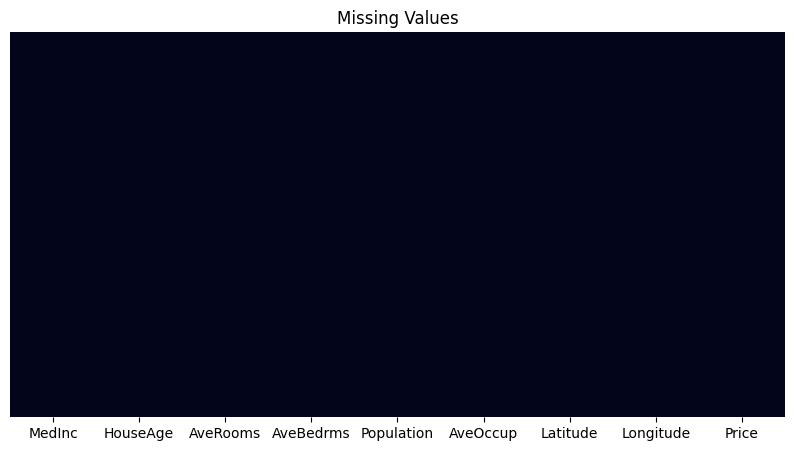

In [ ]:
plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title("Missing Values")
plt.show()

### 3.6 Duplicate records

In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


If duplicate rows are found, investigate them before removing them. Do not automatically delete repeated observations unless they are genuinely unwanted duplicates.

## 4. Exploratory Data Analysis (EDA)

EDA helps us understand the distribution of variables and relationships between features.

- **Univariate analysis:** one variable at a time.
- **Bivariate analysis:** relationship between two variables.
- **Multivariate analysis:** relationships among several variables.

### 4.1 Univariate analysis — histograms

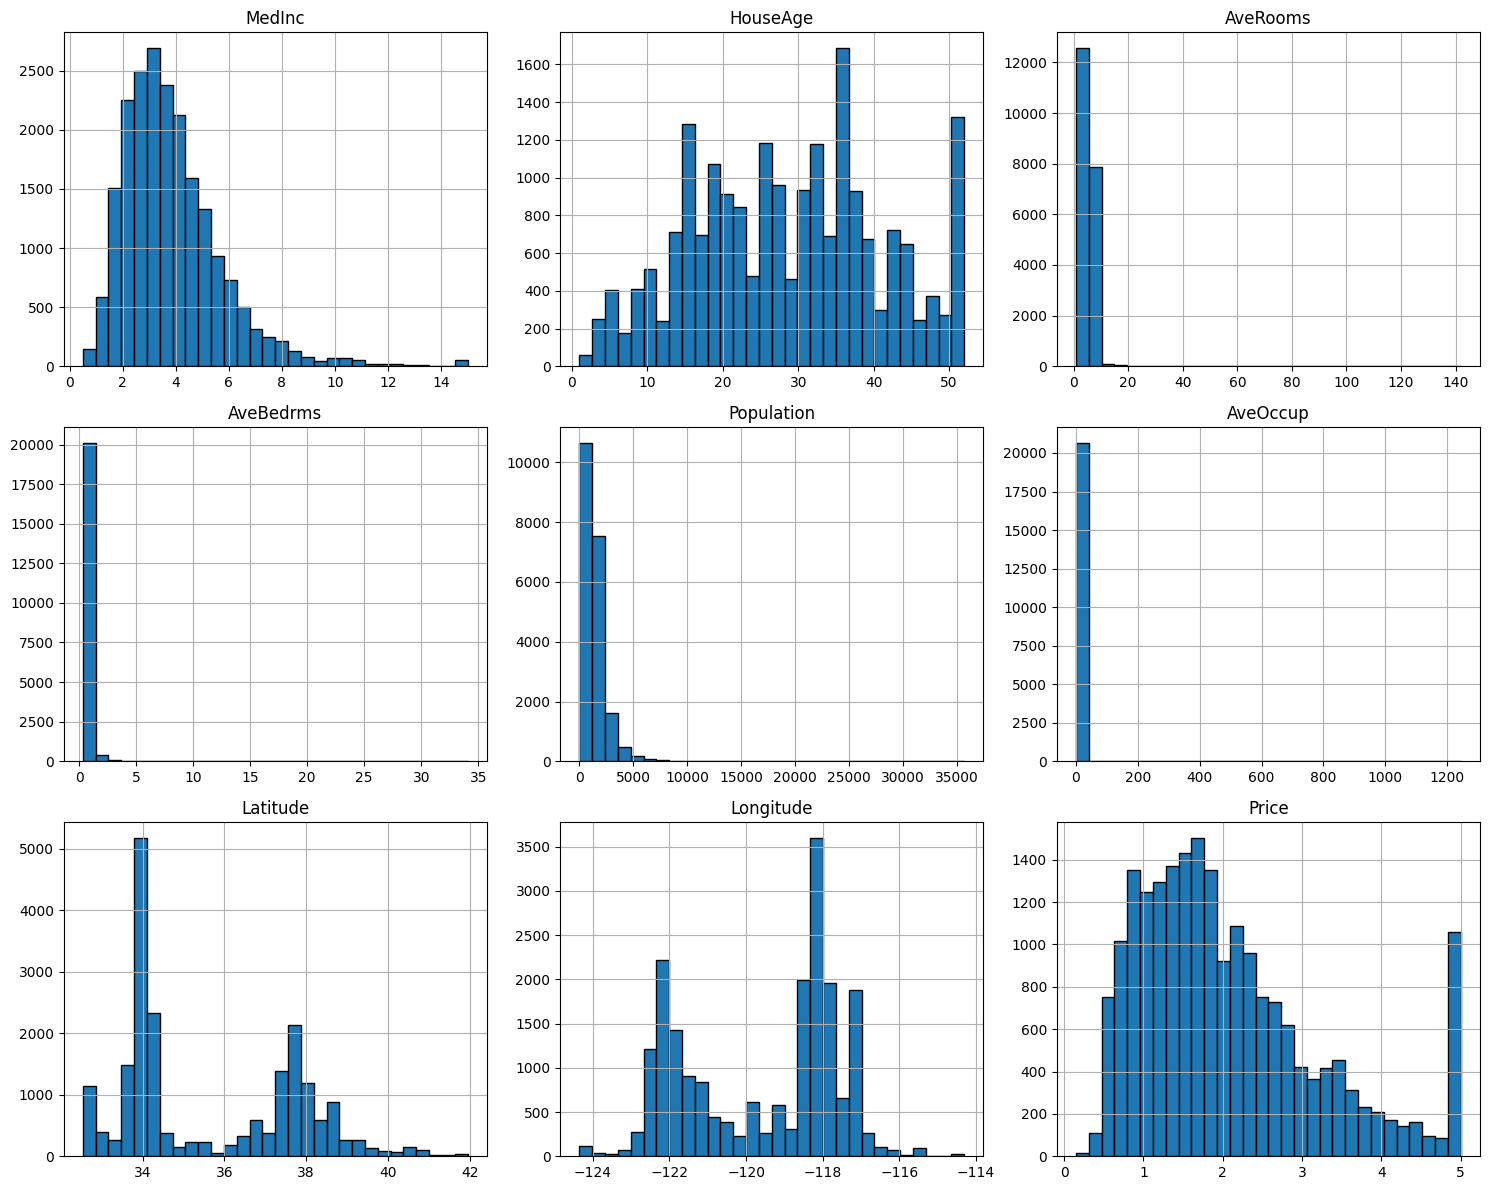

In [ ]:
df.hist(
    figsize=(15, 12),
    bins=30,
    edgecolor="black"
)
plt.tight_layout()
plt.show()

### 4.2 Target distribution

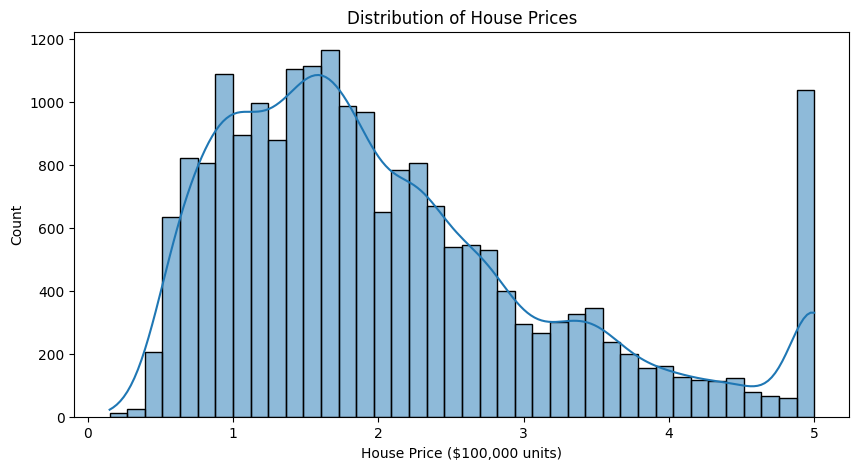

In [ ]:
plt.figure(figsize=(10, 5))
sns.histplot(df["Price"], kde=True, bins=40)
plt.title("Distribution of House Prices")
plt.xlabel("House Price ($100,000 units)")
plt.show()

### 4.3 Boxplots and potential outliers

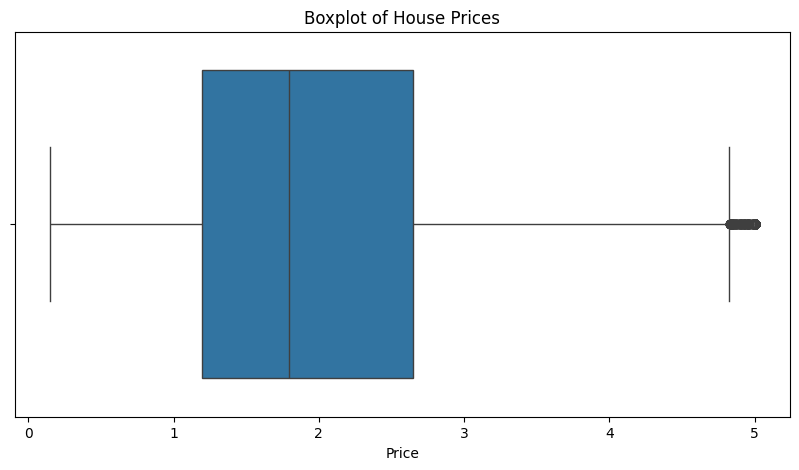

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df["Price"])
plt.title("Boxplot of House Prices")
plt.show()

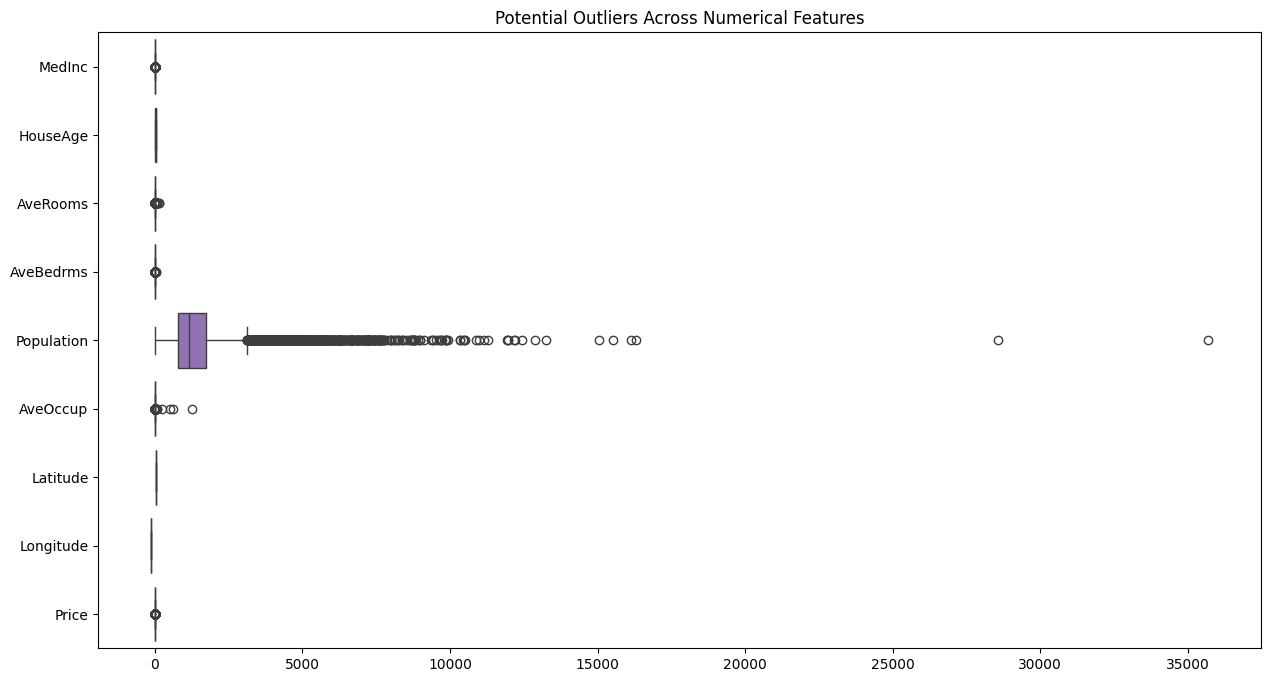

In [ ]:
plt.figure(figsize=(15, 8))
sns.boxplot(data=df, orient="h")
plt.title("Potential Outliers Across Numerical Features")
plt.show()

**Interpretation:** Points beyond boxplot whiskers are potential outliers, not necessarily incorrect records. Keep genuine observations unless there is a clear reason to remove or transform them.

### 4.4 Bivariate analysis — median income vs price

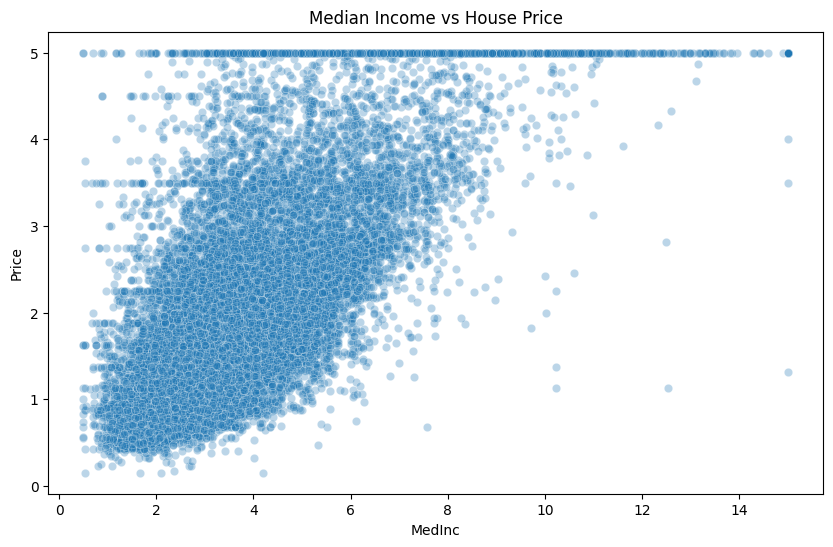

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="MedInc", y="Price", alpha=0.3)
plt.title("Median Income vs House Price")
plt.show()

### 4.5 Each feature against the target

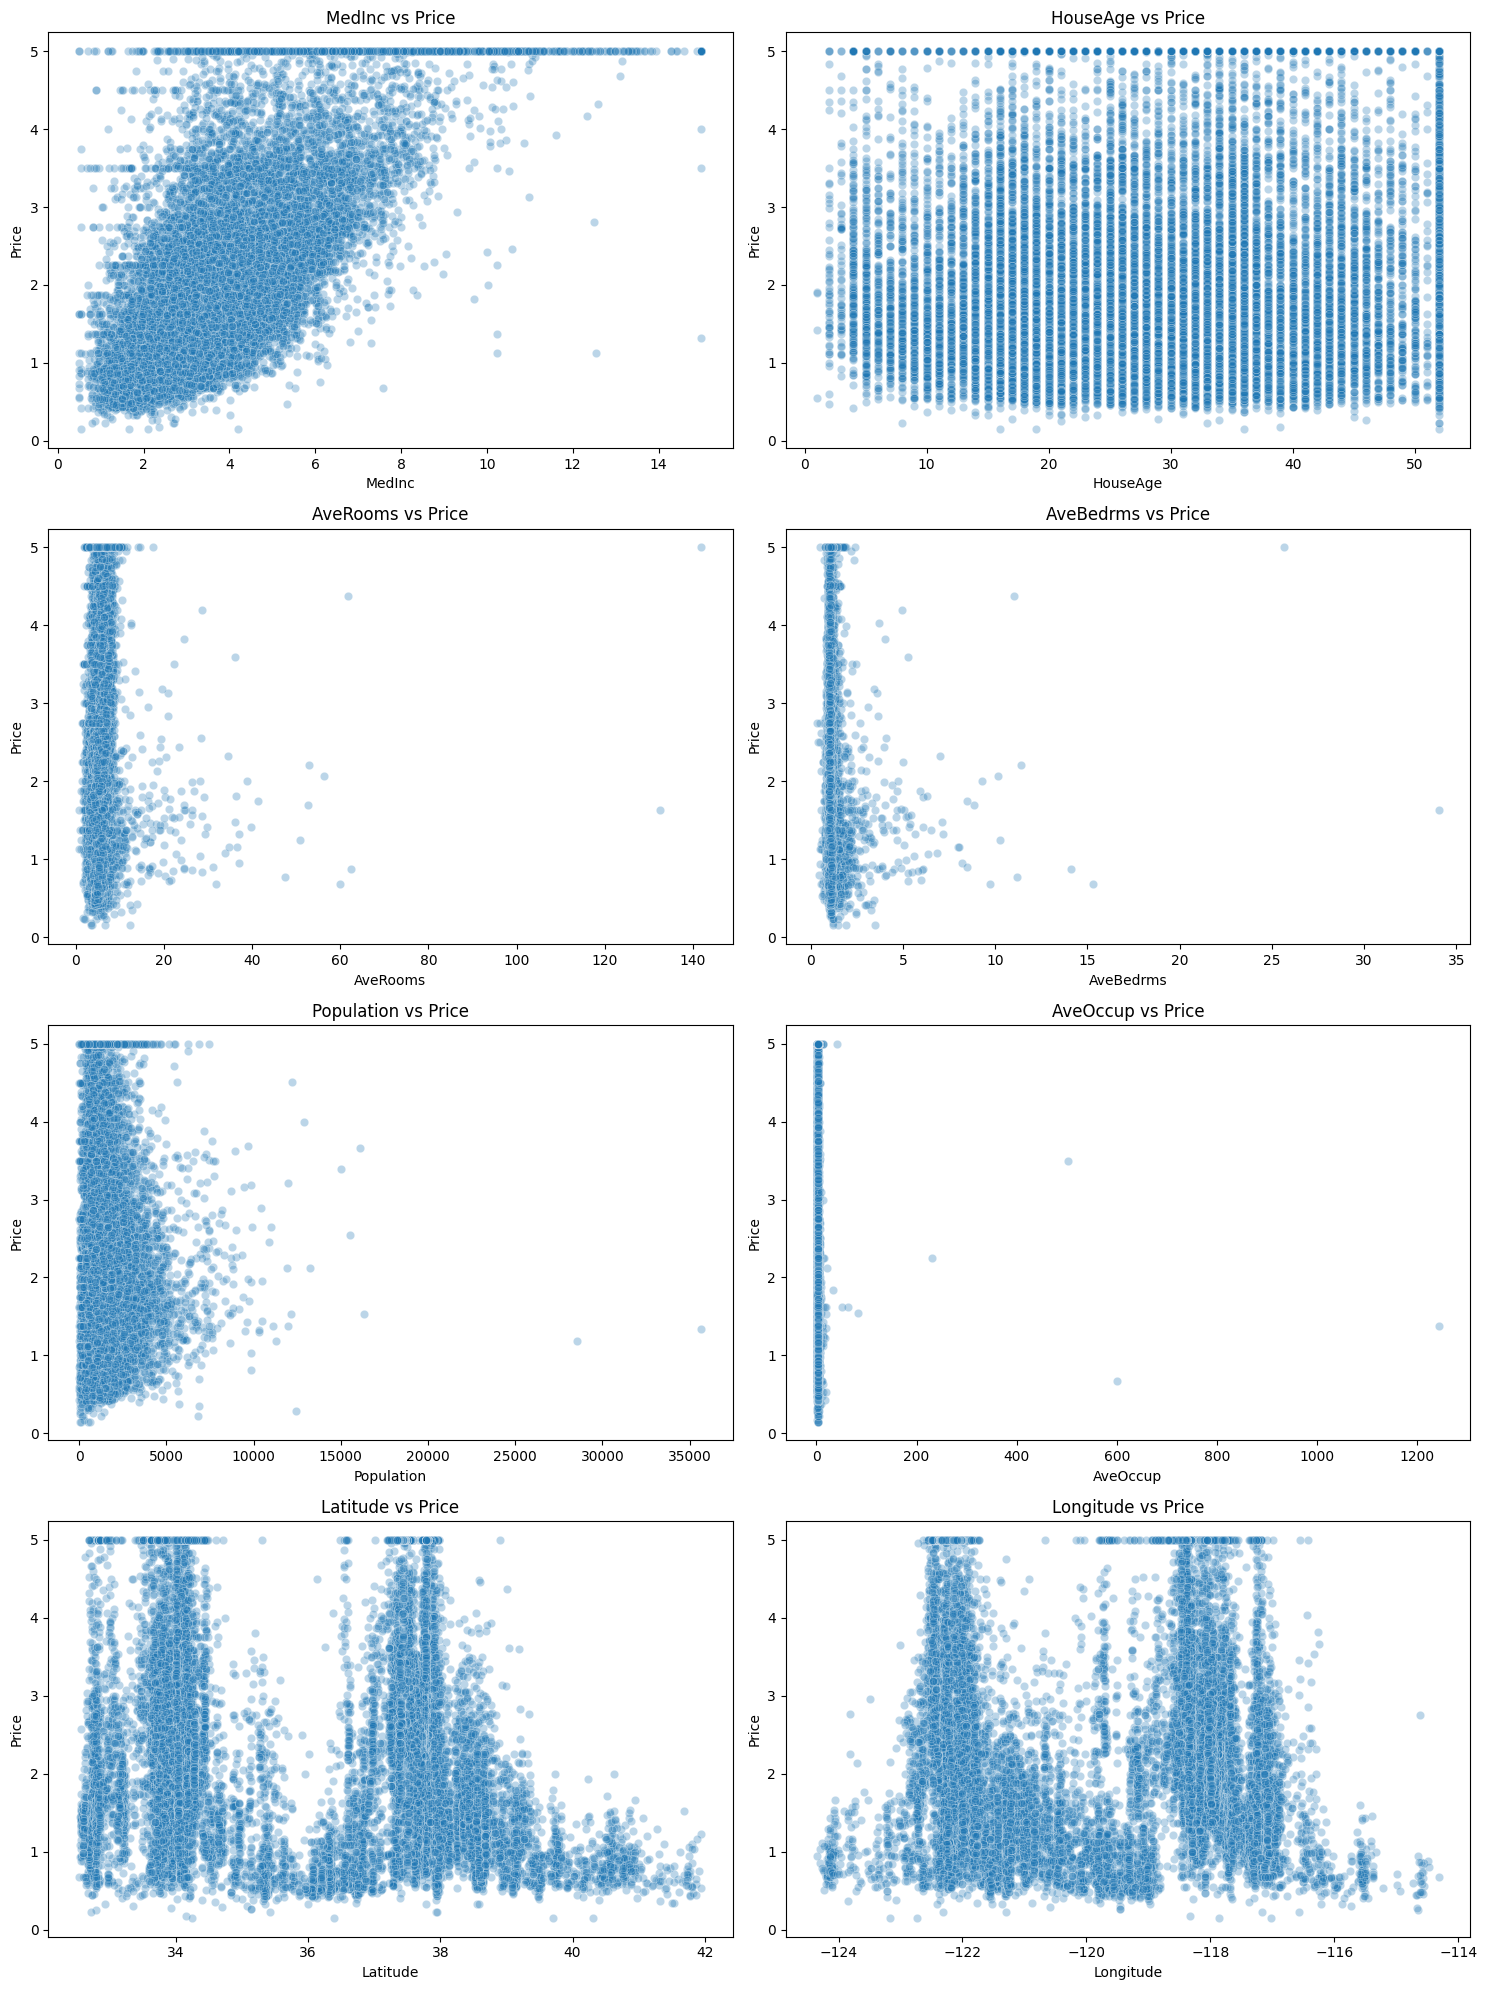

In [ ]:
features = df.drop(columns="Price").columns

fig, axes = plt.subplots(4, 2, figsize=(15, 20))
axes = axes.flatten()

for i, feature in enumerate(features):
    sns.scatterplot(
        data=df,
        x=feature,
        y="Price",
        alpha=0.3,
        ax=axes[i]
    )
    axes[i].set_title(f"{feature} vs Price")

plt.tight_layout()
plt.show()

### 4.6 Regression plot

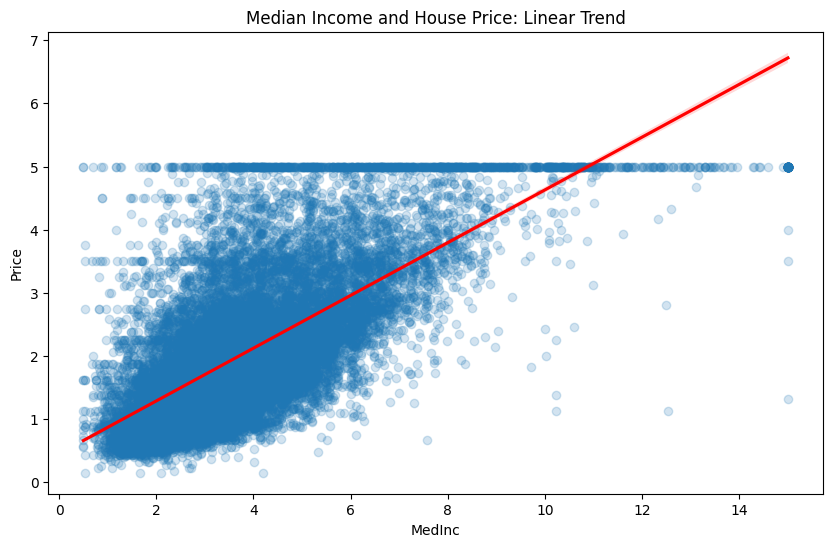

In [ ]:
plt.figure(figsize=(10, 6))
sns.regplot(
    data=df,
    x="MedInc",
    y="Price",
    scatter_kws={"alpha": 0.2},
    line_kws={"color": "red"}
)
plt.title("Median Income and House Price: Linear Trend")
plt.show()

### 4.7 Correlation matrix

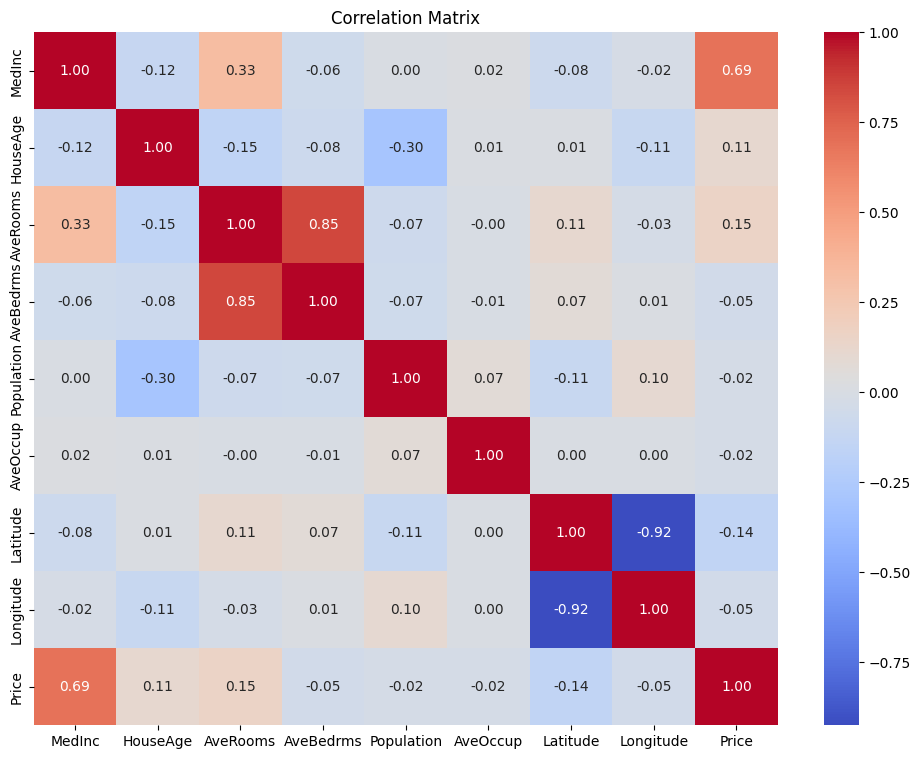

In [ ]:
correlation = df.corr(numeric_only=True)

plt.figure(figsize=(12, 9))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Matrix")
plt.show()

### 4.8 Correlation with the target

In [ ]:
target_corr = correlation["Price"].sort_values(ascending=False)
display(target_corr)

Price         1.000000
MedInc        0.688075
AveRooms      0.151948
HouseAge      0.105623
AveOccup     -0.023737
Population   -0.024650
Longitude    -0.045967
AveBedrms    -0.046701
Latitude     -0.144160
Name: Price, dtype: float64

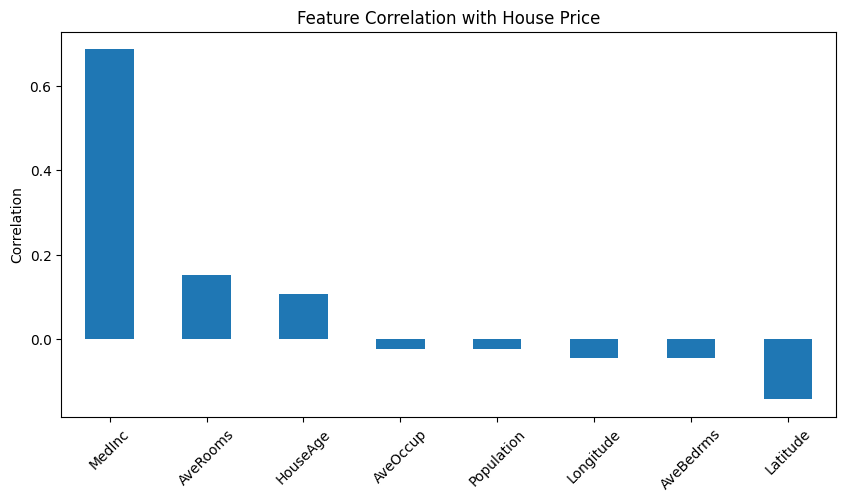

In [ ]:
target_corr.drop("Price").plot(kind="bar", figsize=(10, 5))
plt.title("Feature Correlation with House Price")
plt.ylabel("Correlation")
plt.xticks(rotation=45)
plt.show()

### 4.9 Pair plot

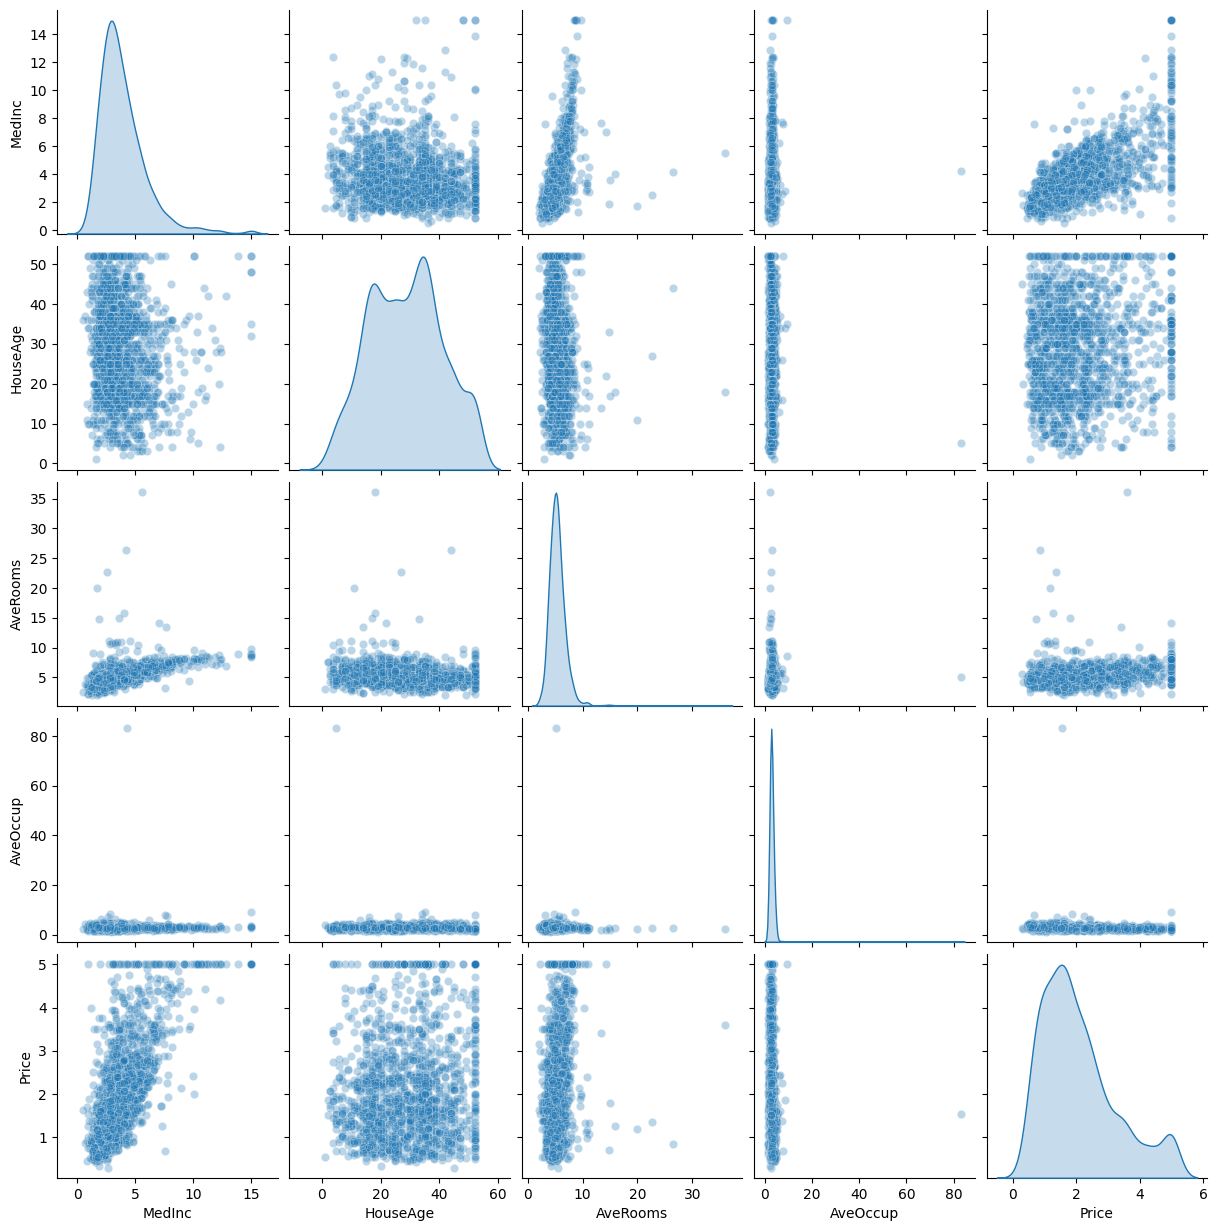

In [ ]:
selected_features = [
    "MedInc",
    "HouseAge",
    "AveRooms",
    "AveOccup",
    "Price"
]

sns.pairplot(
    df[selected_features].sample(1500, random_state=42),
    diag_kind="kde",
    plot_kws={"alpha": 0.3}
)
plt.show()

## 5. Data preprocessing

The original California Housing dataset normally contains no missing values. We will check data quality and retain genuine extreme observations for this baseline model.

### 5.1 Check missing values and duplicates

In [ ]:
print("Missing values per column:")
display(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())

Missing values per column:


MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
Price         0
dtype: int64

Duplicate rows: 0


### 5.2 Define features and target

- `X`: independent variables (input features).
- `y`: dependent variable (target to predict).

For this baseline model, use all eight available features.

In [ ]:
X = df.drop(columns=["Price"])
y = df["Price"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (20640, 8)
Target shape: (20640,)


## 6. Understand Linear Regression

Linear Regression is a supervised learning algorithm used to predict a continuous numerical value.

For multiple features, the model is:

\[
\hat{y} = b_0 + b_1x_1 + b_2x_2 + \cdots + b_nx_n
\]

The model learns coefficients that minimize the sum of squared residuals.

A residual is the difference between an actual value and its prediction:

\[
e_i = y_i - \hat{y}_i
\]

The following cell is a simple conceptual illustration of a least-squares fit.

## 7. Split the dataset into training and testing sets

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (16512, 8)
Testing features: (4128, 8)


## 8. Feature scaling

`StandardScaler` transforms each feature using:

\[
z = \frac{x - \mu}{\sigma}
\]

Fit the scaler only on the training data. Then use the same fitted scaler to transform the test data. This avoids data leakage.

Scaling is not strictly required for ordinary Linear Regression, but it is useful for consistent preprocessing and for comparing with regularized models later.

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 9. Train the Linear Regression model

In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


### 9.1 Inspect the learned parameters

In [ ]:
print("Intercept:", model.intercept_)
print("\nCoefficients:")

for feature, coefficient in zip(X.columns, model.coef_):
    print(f"{feature}: {coefficient:.6f}")

Intercept: -37.02327770606409

Coefficients:
MedInc: 0.448675
HouseAge: 0.009724
AveRooms: -0.123323
AveBedrms: 0.783145
Population: -0.000002
AveOccup: -0.003526
Latitude: -0.419792
Longitude: -0.433708


The intercept is the prediction when all scaled features are zero. Each coefficient describes the change in predicted target for a one-unit increase in that scaled feature, holding the others constant.

## 10. Make predictions on the test set

In [ ]:
y_pred = model.predict(X_test)

print("First 10 predictions:")
print(y_pred[:10])

First 10 predictions:
[0.71912284 1.76401657 2.70965883 2.83892593 2.60465725 2.01175367
 2.64550005 2.16875532 2.74074644 3.91561473]


### 10.1 Compare actual and predicted values

In [ ]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

comparison["Error"] = comparison["Actual"] - comparison["Predicted"]

display(comparison.head(10))

## 11. Evaluate the model

We will use four common regression metrics:

- **MAE:** average absolute prediction error.
- **MSE:** average squared prediction error.
- **RMSE:** square root of MSE, in target units.
- **R²:** proportion of target variation explained by the model relative to a mean-only baseline.

In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation")
print("-------------------------")
print(f"MAE : {mae:.4f}")
print(f"MSE : {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R2  : {r2:.4f}")

Model Evaluation
-------------------------
MAE : 0.5332
MSE : 0.5559
RMSE: 0.7456
R2  : 0.5758


**Remember:** The target is measured in $100,000 units. Multiply MAE or RMSE by 100,000 to express the error in dollars. R² has no units. A negative R² means the model performs worse on the test set than predicting the test-set mean.

## 12. Visualize model performance

### 12.1 Actual vs predicted values

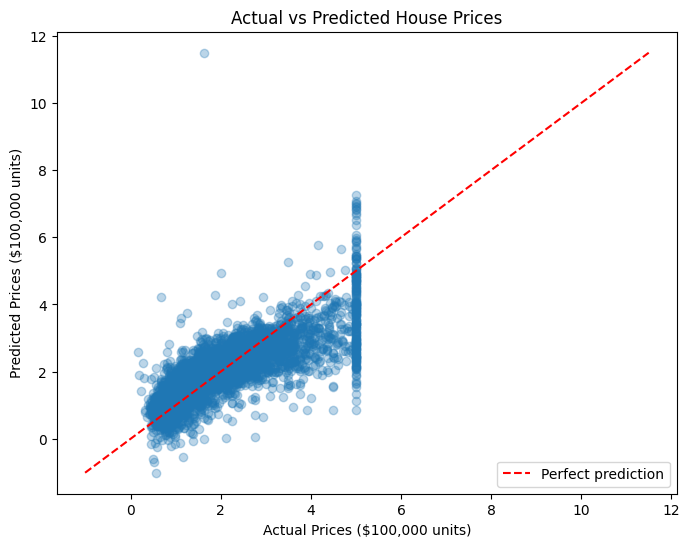

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.3)

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "r--",
    label="Perfect prediction"
)

plt.xlabel("Actual Prices ($100,000 units)")
plt.ylabel("Predicted Prices ($100,000 units)")
plt.title("Actual vs Predicted House Prices")
plt.legend()
plt.show()

### 12.2 Residual distribution

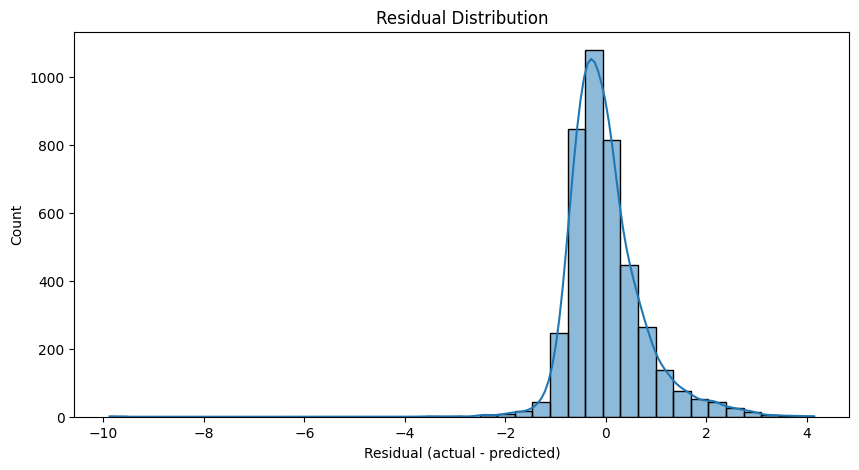

In [ ]:
residuals = y_test - y_pred

plt.figure(figsize=(10, 5))
sns.histplot(residuals, kde=True, bins=40)
plt.title("Residual Distribution")
plt.xlabel("Residual (actual - predicted)")
plt.show()

### 12.3 Residuals vs predicted values

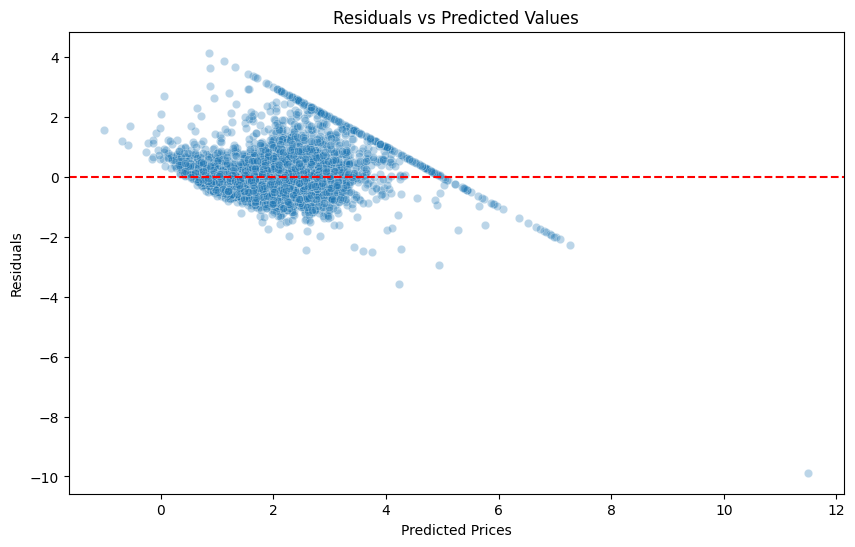

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_pred, y=residuals, alpha=0.3)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Predicted Prices")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Values")
plt.show()

A residual pattern randomly scattered around zero is generally desirable. Curves or funnel-shaped patterns may indicate nonlinearity or non-constant error variance.

## 13. Predict for a new observation

The example below represents a new district. The values are illustrative and must follow the same feature definitions and units as the training data.

In [ ]:
new_data = pd.DataFrame({
    "MedInc": [5.0],
    "HouseAge": [25.0],
    "AveRooms": [5.5],
    "AveBedrms": [1.1],
    "Population": [1000.0],
    "AveOccup": [3.0],
    "Latitude": [34.0],
    "Longitude": [-118.0]
})

new_data = new_data[X.columns]


predicted_price = model.predict(new_data)

print(f"Predicted target: {predicted_price[0]:.4f}")
print(f"Predicted value in dollars: ${predicted_price[0] * 100000:,.2f}")

Predicted target: 2.5384
Predicted value in dollars: $253,838.28


## 14. Implement using a Scikit-learn Pipeline

A Pipeline combines preprocessing and model training. It helps keep the workflow organized and ensures the scaler is fitted only on training data.

In [ ]:
from sklearn.pipeline import Pipeline

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

pipeline.fit(X_train, y_train)

pipeline_predictions = pipeline.predict(X_test)

print("MAE:", mean_absolute_error(y_test, pipeline_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pipeline_predictions)))
print("R2:", r2_score(y_test, pipeline_predictions))